# 02 · Forecasting arena

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional; every airline number below is SIMULATED by this repo's code. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**Question.** Which forecasting method should a spare-parts planner use for each kind of part, and does that choice survive data it was not chosen on?

**Protocol** (frozen before the holdout was run):

* classify parts by demand pattern on **training weeks 0–77 only**;
* score 9–10 methods by rolling-origin evaluation on the **selection** window (origins 78–98, 4-week horizon);
* freeze one champion per (demand class × part class) cell (`outputs/forecasting/champions.csv`, SHA-256 in `outputs/freeze/manifest.json`);
* then score the same methods on the **holdout** (20 unseen seeds, weeks 104–155) and check the champions.

The notebook also benchmarks the methods on REAL public data (Monash Car Parts) and shows how far the data-driven estimates beat the vendor quotes. Only `outputs/holdout/truth_recovery.json`, an evaluation output, touches truth.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
from gnm.forecasting.classify import build_part_attributes
con = duckdb.connect(str(ROOT / "data" / "processed" / "grounded.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).df()

project root: /Users/akashgajjar/grounded-no-more


## 1. Demand classes (ADI / CV²)

Syntetos–Boylan classification: **ADI** is the average gap between demand weeks, and **CV²** is the squared coefficient of variation of the non-zero demand sizes. The cut-offs 1.32 and 0.49 split parts into smooth, erratic, intermittent and lumpy. Fewer than 3 non-zero training weeks is `insufficient_data`. We recompute it here from the history and check it against the exported site data.

In [2]:
mr = q("select pn, week, sum(qty) as qty from material_requests group by all")
demand = mr.pivot(index="pn", columns="week", values="qty").reindex(columns=range(104)).fillna(0)
pm = q("select * from part_master").set_index("pn")
attrs = build_part_attributes(demand, pm.reset_index(), train_weeks=(0, 77))
site = pd.DataFrame(load_json("docs/data/parts.json")["parts"]).set_index("pn")
agree = (attrs.demand_class == site.demand_class.reindex(attrs.index)).mean()
print(f"demand class agrees with docs/data/parts.json for {agree:.0%} of {len(attrs)} parts")
display(pd.crosstab(attrs.demand_class, attrs.part_class, margins=True))

demand class agrees with docs/data/parts.json for 100% of 120 parts


part_class,C,E,R,All
demand_class,,,,
erratic,6,0,0,6
insufficient_data,0,2,0,2
intermittent,4,30,38,72
smooth,35,3,2,40
All,45,35,40,120


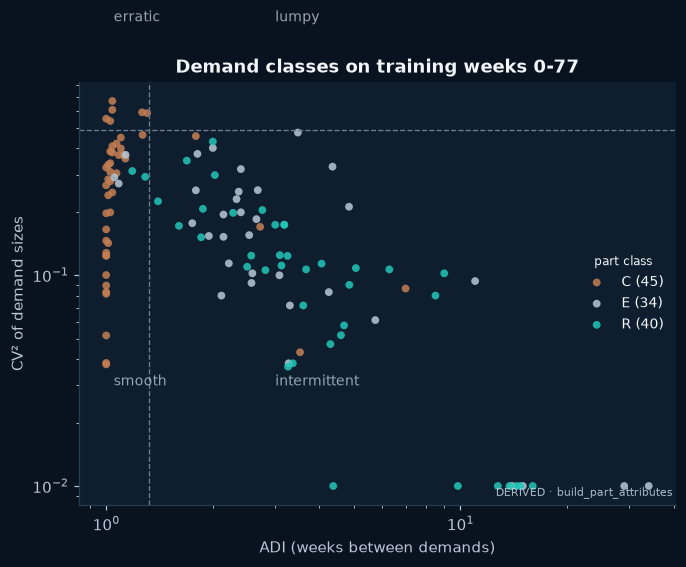

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
cols = {"C": COPPER, "E": TITANIUM, "R": TEAL}
d = attrs.dropna(subset=["adi", "cv2"])
for cls, g in d.groupby("part_class"):
    ax.scatter(g.adi, g.cv2.clip(lower=0.01), s=26, color=cols[cls], alpha=0.85, label=f"{cls} ({len(g)})", edgecolor="none")
ax.axvline(1.32, color=SLATE, lw=0.9, ls="--"); ax.axhline(0.49, color=SLATE, lw=0.9, ls="--")
for x, y, t in [(1.05, 1.6, "erratic"), (1.05, 0.03, "smooth"), (3.0, 0.03, "intermittent"), (3.0, 1.6, "lumpy")]:
    ax.text(x, y, t, color=TITANIUM, fontsize=9, alpha=0.8)
ax.set(xscale="log", yscale="log", xlabel="ADI (weeks between demands)", ylabel="CV² of demand sizes",
       title="Demand classes on training weeks 0-77")
ax.legend(frameon=False, title="part class", title_fontsize=8); stamp(ax, "build_part_attributes", "DERIVED"); plt.show()

Consumables are mostly smooth (frequent line usage). Rotables and expendables are mostly intermittent: one removal every few weeks, almost always a single unit. Intermittent demand is where classical forecasting struggles and where the Croston family (Croston, SBA, TSB) and aggregation methods (ADIDA, IMAPA) come in.

## 2. Leaderboard: selection vs holdout, with confidence intervals

MASE (mean absolute scaled error, < 1 beats the naive in-sample benchmark) per method and part class, with 95 % bootstrap CIs over parts. The left dot in each pair is the selection window, the right one the holdout.

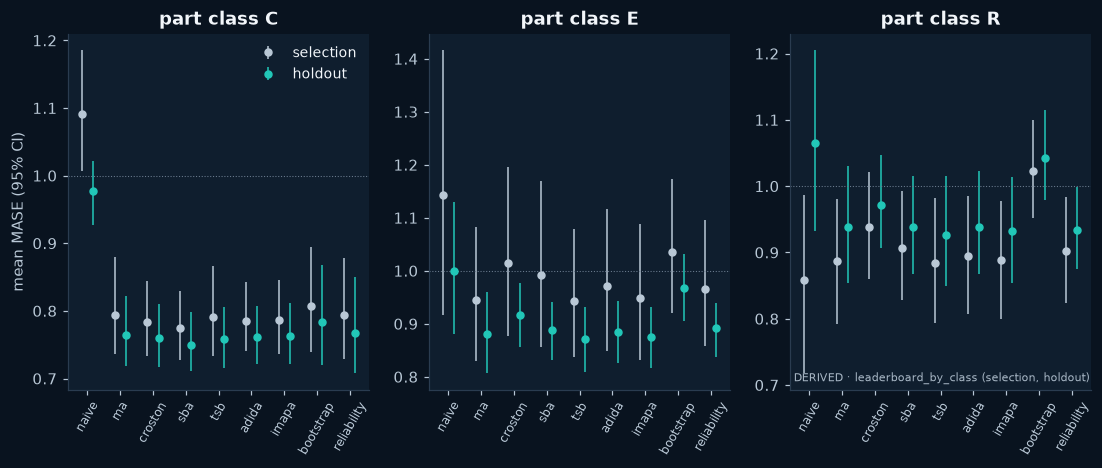

,part_class,method,mase_sel,mase_hol,pinball_q90_sel,pinball_q90_hol,cov_q90_sel,cov_q90_hol
0,C,adida,0.785,0.761,1.787,1.699,0.822,0.839
1,C,bootstrap,0.808,0.783,1.545,1.551,0.948,0.959
2,C,croston,0.783,0.759,1.713,1.619,0.833,0.856
3,C,imapa,0.787,0.763,1.784,1.699,0.822,0.837
4,C,ma,0.795,0.764,1.842,1.685,0.807,0.843
5,C,naive,1.091,0.977,5.241,4.386,0.648,0.646
6,C,reliability,0.793,0.767,1.719,1.541,0.856,0.870
7,C,sba,0.775,0.750,1.864,1.687,0.785,0.820
8,C,tsb,0.790,0.758,1.718,1.641,0.819,0.848
10,E,adida,0.971,0.885,0.360,0.286,0.900,0.943


In [4]:
sel = pd.read_csv(ROOT / "outputs/forecasting/leaderboard_by_class.csv")
hol = pd.read_csv(ROOT / "outputs/holdout/forecast_leaderboard_by_class.csv")
methods = [m for m in ["naive", "ma", "croston", "sba", "tsb", "adida", "imapa", "bootstrap", "reliability"] if m in set(sel.method)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=False)
for ax, cls in zip(axes, ["C", "E", "R"]):
    for j, (df, col, lab, off) in enumerate([(sel, TITANIUM, "selection", -0.17), (hol, TEAL, "holdout", 0.17)]):
        g = df[(df.part_class == cls)].set_index("method").reindex(methods)
        x = np.arange(len(methods)) + off
        ax.errorbar(x, g.mase, yerr=[g.mase - g.mase_ci_lo, g.mase_ci_hi - g.mase], fmt="o", color=col, ms=4.5,
                    elinewidth=1, capsize=0, label=lab)
    ax.set_xticks(range(len(methods))); ax.set_xticklabels(methods, rotation=60, fontsize=8)
    ax.set_title(f"part class {cls}"); ax.axhline(1, color=SLATE, lw=0.7, ls=":")
axes[0].set_ylabel("mean MASE (95% CI)"); axes[0].legend(frameon=False)
stamp(axes[-1], "leaderboard_by_class (selection, holdout)", "DERIVED"); plt.show()
cmp = sel.merge(hol, on=["part_class", "method"], suffixes=("_sel", "_hol"))[["part_class", "method", "mase_sel", "mase_hol", "pinball_q90_sel", "pinball_q90_hol", "cov_q90_sel", "cov_q90_hol"]]
display(cmp[cmp.method.isin(methods)].round(3))

Two things matter for a planner:

* **Point accuracy is a near tie.** Within a part class the methods' CIs overlap heavily, on both selection and holdout. No single method dominates.
* **The tails matter more than the mean for stocking.** The q90 pinball loss and the q90 coverage show which methods produce usable upper quantiles. The reliability-exposure model (removal rate per flight hour or cycle, with a Gamma prior at the vendor quote) and the Willemain bootstrap give the best tails. That is why the policies stock rotables from the reliability rate rather than from the MASE champion (decision POL-3).

## 3. Champion check on the holdout

Were the frozen champions still good on unseen data? `champion_rank` is the champion's holdout MASE rank among the methods in its cell (1 = best).

In [5]:
cc = pd.read_csv(ROOT / "outputs/holdout/forecast_champion_check.csv")
cc["gap_to_best"] = cc.champion_mase - cc.best_mase
display(cc.round(3))
print(f"champion best on holdout in {(cc.champion_rank == 1).sum()} of {len(cc)} cells; "
      f"median rank {cc.champion_rank.median():.0f} of {int(cc.n_methods.max())}")

,demand_class,part_class,n_parts,champion,champion_mase,best_in_hindsight,best_mase,champion_rank,n_methods,gap_to_best
0,erratic,C,6,tsb,0.724,reliability,0.711,6,9,0.013
1,insufficient_data,E,2,tsb,1.031,naive,0.576,2,9,0.455
2,intermittent,C,4,imapa,1.054,reliability,1.008,6,9,0.045
3,intermittent,E,30,tsb,0.879,tsb,0.879,1,9,0.000
4,intermittent,R,38,naive,1.072,tsb,0.932,9,9,0.139
5,smooth,C,35,sba,0.723,sba,0.723,1,9,0.000
6,smooth,E,3,sba,0.674,reliability,0.650,2,9,0.024
7,smooth,R,2,sba,0.814,reliability,0.807,2,9,0.007


champion best on holdout in 2 of 8 cells; median rank 2 of 9


The honest reading: the frozen champion is best on the holdout in 2 of 8 cells and second in 3 more, usually within a few hundredths of the best. Two cells stand out. The 2-part `insufficient_data` cell is noise, and the intermittent-rotable champion (`naive`, chosen by MASE) is last of 9. This is the known MASE artefact on 0/1 series: on intermittent data, MASE rewards a forecast that copies the last week. It was kept as frozen, not re-picked after seeing the holdout. It does no damage, because rotable stocking uses the reliability rate, not the MASE champion. The cell sizes (2–38 parts) also explain why rankings move.

## 4. REAL-data benchmark: Monash Car Parts

To show the methods are implemented correctly and behave as the literature expects, they are run on the public **Car Parts** dataset (2,674 monthly series, 12-month horizon). Data provenance **REAL**, metrics **DERIVED**. Source: Godahewa, Bergmeir, Webb, Hyndman & Montero-Manso (2021), Monash Time Series Forecasting Archive, Zenodo record 4656021, licence CC BY 4.0 (original data: Hyndman 2015, R package `expsmooth`).

REAL data / DERIVED metrics · CC BY 4.0 · https://zenodo.org/records/4656021


,n_mase_defined,mase,mase_ci_lo,mase_ci_hi,mase_median,bias,cov_q90,pinball_q90
method,,,,,,,,
zero,2658,0.777,0.728,0.826,0.372,-0.391,0.261,4.226
naive,2658,1.226,1.147,1.311,0.528,0.089,0.475,3.182
ma,2658,1.103,1.047,1.158,0.714,0.056,0.749,1.466
croston,2658,1.327,1.271,1.388,0.904,0.124,0.842,1.509
sba,2658,1.258,1.203,1.317,0.839,0.058,0.815,1.575
tsb,2658,1.069,1.021,1.124,0.686,0.040,0.812,1.236
adida,2658,1.061,1.016,1.109,0.708,0.018,0.830,1.284
imapa,2658,1.056,1.011,1.108,0.694,0.030,0.833,1.185
bootstrap,2658,1.274,1.231,1.325,0.913,0.206,0.909,1.469


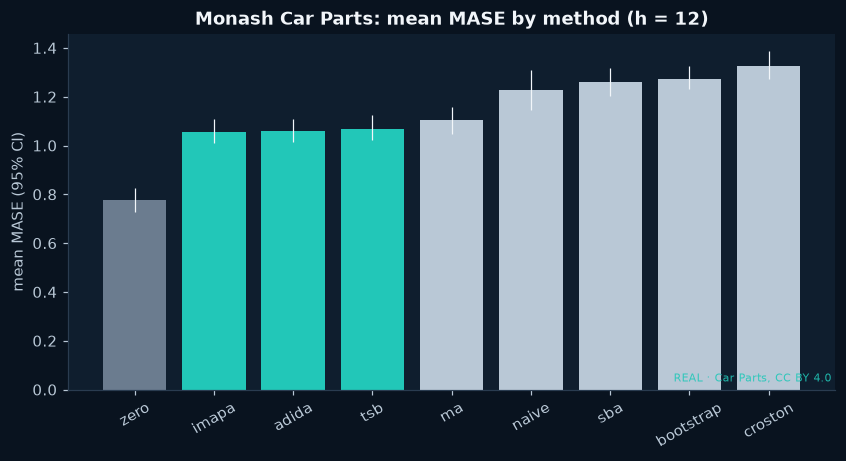

In [6]:
mon = load_json("outputs/forecasting/monash_benchmark.json")
print(mon["data_provenance"], "data /", mon["provenance"], "metrics ·", mon["licence"], "·", mon["source_url"])
mr_ = pd.DataFrame(mon["results"]).set_index("method")
display(mr_[["n_mase_defined", "mase", "mase_ci_lo", "mase_ci_hi", "mase_median", "bias", "cov_q90", "pinball_q90"]].round(3))
order = mr_.sort_values("mase").index
fig, ax = plt.subplots()
colors = [SLATE if m == "zero" else (TEAL if m in ("imapa", "adida", "tsb") else TITANIUM) for m in order]
ax.bar(order, mr_.loc[order, "mase"], color=colors,
       yerr=[mr_.loc[order, "mase"] - mr_.loc[order, "mase_ci_lo"], mr_.loc[order, "mase_ci_hi"] - mr_.loc[order, "mase"]],
       error_kw=dict(ecolor=ICE, lw=0.8))
ax.set(ylabel="mean MASE (95% CI)", title="Monash Car Parts: mean MASE by method (h = 12)")
ax.tick_params(axis="x", rotation=30); stamp(ax, "Car Parts, CC BY 4.0", "REAL"); plt.show()

As in the literature: the all-zero forecast wins on MASE (many series fade out during the test year, and MAE-type metrics reward the median, which is often 0). That is why `zero` is a benchmark only and never a champion. Among the eligible methods, IMAPA, ADIDA and TSB lead at about 1.06, and the bootstrap gives the best q90 coverage. The published archive values (SES 0.897 etc.) are context only, because their MASE scaling is not stated.

## 5. Truth recovery: do the estimates beat the vendor quotes?

After the holdout, the evaluation compared the history-based estimates with the hidden truth (`outputs/holdout/truth_recovery.json`, DERIVED). The metric is the median absolute log error |ln(estimate / true)|: 0.10 is about 10 % off.

,param,n,vendor_quote,estimate,share_estimate_closer
0,MTBUR (all),75,0.369,0.109,0.787
1,MTBUR (E),35,0.282,0.096,0.771
2,MTBUR (R),40,0.416,0.126,0.800
3,purchase lead time,120,0.066,0.064,NaN


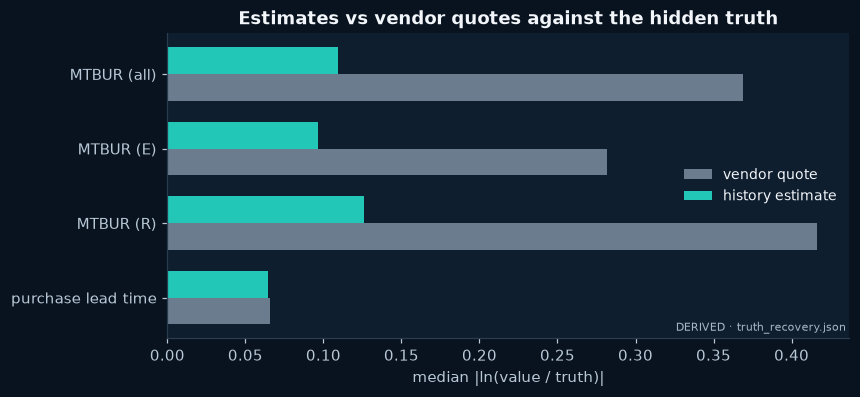

,pn,true,est,quoted,changed
0,GN-30-E025,165.160958,156.4792,65.2,True


In [7]:
tr = load_json("outputs/holdout/truth_recovery.json")
rows = [dict(param=f"MTBUR ({k})", n=v["n_parts"], vendor_quote=v["quoted_mdale"], estimate=v["estimated_mdale"],
             share_estimate_closer=v["share_estimate_closer"]) for k, v in tr["reliability"].items()]
lt = tr["lead_time"]
rows.append(dict(param="purchase lead time", n=lt["n_parts"], vendor_quote=lt["quoted_mdale"], estimate=lt["estimated_mdale"],
                 share_estimate_closer=np.nan))
trd = pd.DataFrame(rows); display(trd.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(trd))
ax.barh(y + 0.18, trd.vendor_quote, height=0.36, color=SLATE, label="vendor quote")
ax.barh(y - 0.18, trd.estimate, height=0.36, color=TEAL, label="history estimate")
ax.set_yticks(y); ax.set_yticklabels(trd.param); ax.invert_yaxis()
ax.set(xlabel="median |ln(value / truth)|", title="Estimates vs vendor quotes against the hidden truth")
ax.legend(frameon=False); stamp(ax, "truth_recovery.json", "DERIVED"); plt.show()
display(pd.DataFrame(lt["changed_parts"]))

The reliability posterior cuts the MTBUR error from about 37 % to about 11 % and is closer than the quote for 79 % of parts. Lead times were mostly quoted correctly, so the estimate only ties the quote overall. On the one part whose supplier changed (PS4, GN-30-E025) it is decisive: 156 days estimated against 165 true, where the master file still says 65.

## Summary

* Point forecasts of intermittent spares are a near tie. Pick methods for their **distribution** (coverage, pinball), not their MASE alone.
* The frozen champions were checked honestly on the holdout. The weakest (naive for intermittent rotables) is documented and harmless, because rotables are stocked from the reliability rate.
* On REAL data the implementations reproduce the literature's pattern.
* Data-driven rates and lead times beat vendor quotes by a wide margin, which is the core reason the new policies outperform P0.

Next: `03_policy_and_frontier.ipynb`.